In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Aplicação da formula da corda
### Aplicação geral

In [32]:
def calcular_coeficiente_Cn_1(n, L):
    integrando = lambda x: f(x) * np.sin((n * np.pi / L) * x)
    integral, _ = quad(integrando, 0, L)
    return (2 / L) * integral


def calcular_deslocamento_1(x_array, t, L, a, N_termos):
    y = np.zeros_like(x_array)
    for n in range(1, N_termos + 1, 1):
        Cn = calcular_coeficiente_Cn_1(n, L)
        y += Cn * np.sin((n * np.pi / L) * x_array) * np.cos((n * np.pi / L) * a * t)
    return y

In [33]:
def calcular_coeficiente_Cn_2(n, L, a):
    integrando = lambda x: g(x) * np.sin(n * np.pi * x / L)
    integral, _ = quad(integrando, 0, L)
    return (2.0 / (np.pi * a * n)) * integral


def calcular_deslocamento_2(x_array, t, L, a, N_termos):
    y = np.zeros_like(x_array)
    for n in range(1, N_termos + 1, 1):
        Cn = calcular_coeficiente_Cn_2(n, L, a)
        y += Cn * np.sin((n * np.pi / L) * x_array) * np.sin((n * np.pi / L) * a * t)
    return y

# Configuração da plotagem dos gráficos 2d e 3d

In [34]:
def plotar_2d(L, a, N_termos, tempos_para_plotar):
    """
    Gera um gráfico 2D clássico, sobrepondo o estado da corda em diferentes instantes de tempo.
    """
    x = np.linspace(0, L, 200)
    plt.figure(figsize=(10, 6))

    for t in tempos_para_plotar:
        y_calculado = calcular_deslocamento_1(x, t, L, a, N_termos) + calcular_deslocamento_2(x, t, L, a, N_termos)
        plt.plot(x, y_calculado, label=f"t = {t}s")


    plt.title("Propagação da Onda ao Longo do Tempo")
    plt.xlabel("Posição na Corda (x)")
    plt.ylabel("Deslocamento (y)")
    plt.axhline(0, color="black", linewidth=0.5)
    plt.legend()
    plt.grid(True, linestyle=":")
    plt.show()


# Parametros globais

In [35]:
COMPRIMENTO_L = np.pi
A = 1
TERMOS_FOURIER = 10
TEMPO_TOTAL = 2.0
tempos = np.linspace(1, TEMPO_TOTAL, 5)  # 5 instantes de tempo para plotar

# Definição do f(x) para a condição inicial
## Utilizando f(x) = x

In [38]:
def f(x):
    return 0

def g(x):
    return 0

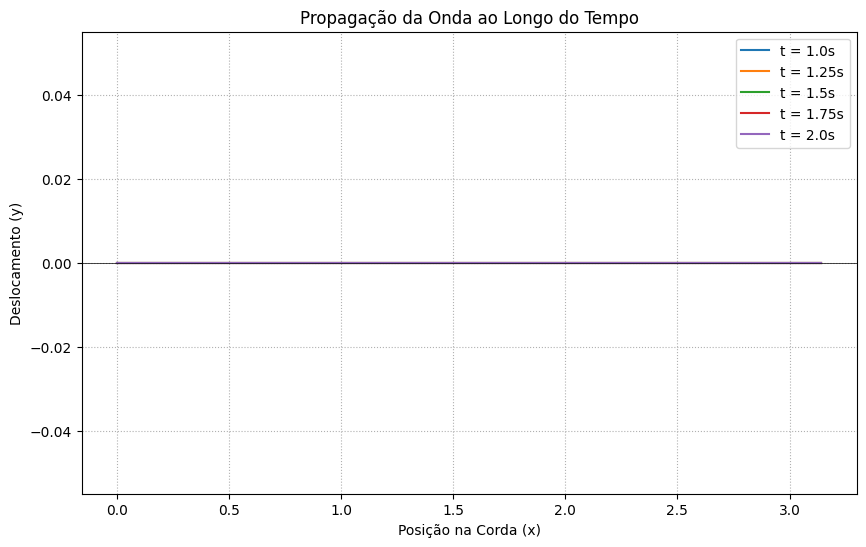

In [39]:
plotar_2d(COMPRIMENTO_L, A, TERMOS_FOURIER, tempos)
